# humor-me decisions: data and labels

Evidence for the decisions about transcripts and rJokes: bit segmentation (Exp 1), rJokes prep (Exp 2), and the R2 labels and what they can support (Exp 9, 10, 11, 12). Experiment numbers are global across the `decisions*.ipynb` notebooks; the index is [decisions.ipynb](decisions.ipynb).

**How to use it**
- Results load from `reports/metrics/*.json` (cached by parameters), so nothing recomputes unless you ask. Some cells read local-only files under `data/`; those run only on a machine that has them.
- Change a parameter in a cell and that experiment recomputes and the cache updates. Set `RERUN = True` after the import in the setup cell to recompute everything.
- Every claim has a **✅ / ❌ check** under it. If a change flips one to ❌, the decision it backs needs revisiting.
- Before committing: `python scripts/run_notebook.py` (restart + run all, clean metadata).

Rules: logic lives in modules; cells only call, display and check. Vocabulary: [glossary](../docs/wiki/glossary.md).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd() if Path.cwd().name == "notebooks" else Path.cwd() / "notebooks"))
from decisions_common import RERUN, check, show
from IPython.display import display
from sim.cache import load, run_or_load

## Exp 1 Bit segmentation on stand-up transcripts (2026-10-21)

**Decision:** S4 asks Gemini for bit boundaries on whole sets; a bit = smallest standalone stretch.
**Where it fits:** the transcript pipeline that gives the report its "how a comedian builds a set"
evidence ([stand-up structure](../docs/wiki/standup-structure.md)). Paused since 2026-10-26.
**Question:** does an LLM find bit boundaries well enough, against hand labels and an
evenly-spaced baseline?

**How to read:** F1 = boundary matches (higher better); Pk / WindowDiff = segmentation error
(lower better). *Not re-runnable here*: needs Gemini + the local transcripts
(`python -m pipeline.bits`, then `python -m pipeline.validate`); this is the stored snapshot.

In [2]:
seg = load("segmentation_bargatze", {"source": "python -m pipeline.validate (S6)", "set": "nate-bargatze_hello-world_2023"})["sets"][0]
rows = []
for level in ("bits", "threads"):
    for who in ("llm", "even_baseline"):
        m = seg[level][who]
        rows.append(f"| {level} | {who} | {m['f1']:.2f} | {m['precision']:.2f} | {m['recall']:.2f} | {m['pk']:.3f} | {m['windowdiff']:.3f} |")
show("| Level | Segmenter | F1 | P | R | Pk | WindowDiff |\n|---|---|---|---|---|---|---|\n" + "\n".join(rows)
     + f"\n\nCallbacks: {seg['callbacks']['hyp']} found of {seg['callbacks']['ref']} hand-labeled.")
check("LLM bit boundaries beat the even-spacing baseline by > 0.5 F1",
      seg["bits"]["llm"]["f1"] - seg["bits"]["even_baseline"]["f1"] > 0.5)
check("Callbacks are not found yet (why they need their own pass)", seg["callbacks"]["hyp"] == 0)

| Level | Segmenter | F1 | P | R | Pk | WindowDiff |
|---|---|---|---|---|---|---|
| bits | llm | 0.80 | 0.83 | 0.77 | 0.146 | 0.171 |
| bits | even_baseline | 0.20 | 0.21 | 0.20 | 0.505 | 0.524 |
| threads | llm | 0.63 | 0.86 | 0.50 | 0.263 | 0.278 |
| threads | even_baseline | 0.07 | 0.10 | 0.06 | 0.465 | 0.484 |

Callbacks: 0 found of 3 hand-labeled.

✅ **LLM bit boundaries beat the even-spacing baseline by > 0.5 F1**

✅ **Callbacks are not found yet (why they need their own pass)**

True

## Exp 2 rJokes prep (2026-10-26: pause transcripts, rJokes + simulator first)

**Decision:** stop spending Gemini quota on transcripts; use rJokes as the working joke dataset.
**Where it fits:** sim priors and the human-preference work ([rJokes](../docs/wiki/rjokes-dataset.md)).
**How to read:** row counts through each cleaning step; repost spread is the **noise ceiling**
(the same joke text scoring very differently). *Needs the local dataset to re-run*
(`python -m pipeline.rjokes`); stored snapshot shown.

In [3]:
rj = load("rjokes_prep", {"source": "python -m pipeline.rjokes (R1)", "min_words": 4, "max_words": 200})
show(f"""| Step | Jokes |
|---|---|
| Official splits | {rj['rows_in']:,} |
| After deduping reposts | {rj['after_dedupe']:,} |
| After 4–200 word filter | {rj['after_length']:,} |

Reposted texts: {rj['reposted']:,}; median score spread between posts of the same text:
**{rj['repost_spread_median']}** on the ln scale (≈ 7× upvotes).""")
check("Enough jokes remain for a 30k labeled sample (> 300k)", rj["after_length"] > 300_000)
check("Repost noise is large (median spread ≥ 2 on the ln scale)", rj["repost_spread_median"] >= 2)

| Step | Jokes |
|---|---|
| Official splits | 432,457 |
| After deduping reposts | 419,446 |
| After 4–200 word filter | 402,981 |

Reposted texts: 6,971; median score spread between posts of the same text:
**2** on the ln scale (≈ 7× upvotes).

✅ **Enough jokes remain for a 30k labeled sample (> 300k)**

✅ **Repost noise is large (median spread ≥ 2 on the ln scale)**

True

## Exp 9 R2 labels vs a hand check (2026-10-31)

**Decision:** rJokes is for mode statistics only, never joke material (safety flags unreliable).
**Question:** can the R2 judge's mode and safety labels (Qwen2.5-7B, PR #20) be trusted before they
feed the human-vs-judge mode ranking (explore-next #1)?
**Where it fits:** the per-mode upvote percentiles that would replace the sim's `base`
([rJokes](../docs/wiki/rjokes-dataset.md)).
**Sample:** 105 jokes, 15 per judge mode, marked by hand (y / n + better mode / ? = joke didn't land,
no mode assignable / skipped, mostly NSFW). Labels in `data/labels/rjokes_hand_check.csv` (no joke text).
**How to read:** precision = judged rows the human agreed with, per judge mode (Wilson 95% CI, ~12 rows
each, so wide). The sample is stratified, so the overall figure is re-weighted by each mode's share of
all labels (90k). Safety notes were written only where something stood out: judge *misses* are measurable,
false alarms are not. No pass criterion was fixed before the check; the checks below state findings.
*Needs the local `modes.jsonl` to re-run*; stored snapshot shown.

In [4]:
from explorer import hand_check
hc = run_or_load("hand_check", hand_check.run, rerun=RERUN,
                 hand="data/labels/rjokes_hand_check.csv", modes="data/processed/rjokes/modes.jsonl")
show(hand_check.table(hc))
pm, sf = hc["per_mode"], hc["safety"]
named = {k: v for k, v in hc["misses"].items() if not k.endswith("?")}
check(f"Mode labels mostly hold: {hc['weighted_precision']:.0%} precision at the labeled mode mix (≥ 90%)",
      hc["weighted_precision"] >= 0.90)
check(f"Absurdist is the hardest to verify: {pm['absurdist']['unsure']} of "
      f"{pm['absurdist']['y'] + pm['absurdist']['n'] + pm['absurdist']['unsure']} judged couldn't be placed (≥ 1/3)",
      pm["absurdist"]["unsure"] * 3 >= pm["absurdist"]["y"] + pm["absurdist"]["n"] + pm["absurdist"]["unsure"])
check(f"Misses lean to wordsmith: {sum(v for k, v in named.items() if k.endswith('wordsmith'))} of "
      f"{sum(named.values())} misses with a known mode were puns",
      sum(v for k, v in named.items() if k.endswith("wordsmith")) * 2 > sum(named.values()))
check(f"Decision holds: judge safety flags miss what a human sees → rJokes used for mode statistics only: {sf['judge_flagged_any_of_those']} of "
      f"{sf['human_flagged']} human-flagged rows flagged by the judge",
      sf["judge_flagged_any_of_those"] <= sf["human_flagged"] // 4)

| Judge mode | Share of labels | y | n | ? | skipped | Precision | 95% CI |
|---|---|---|---|---|---|---|---|
| wordsmith | 28.2% | 11 | 0 | 1 | 3 | 100% | 74%–100% |
| cynic | 27.2% | 10 | 1 | 1 | 3 | 91% | 62%–98% |
| neurotic | 20.5% | 6 | 1 | 2 | 6 | 86% | 49%–97% |
| observer | 11.5% | 11 | 3 | 0 | 1 | 79% | 52%–92% |
| absurdist | 10.7% | 7 | 0 | 6 | 2 | 100% | 65%–100% |
| optimist | 1.3% | 9 | 2 | 1 | 3 | 82% | 52%–95% |
| none | 0.6% | 14 | 1 | 0 | 0 | 93% | 70%–99% |

Precision on judged rows: **89%** (81%–95%); re-weighted to the labeled mode mix: **92%**.
Misses (judge → human): observer → wordsmith ×2, cynic → absurdist ×1, neurotic → wordsmith ×1, none → wordsmith ×1, observer → ? ×1, optimist → wordsmith ×1, optimist → ? ×1

| Human safety note | Rows | Judge flagged it too |
|---|---|---|
| about_bodies | 1 | 0 |
| outside schema | 4 | 0 |
| sexual | 8 | 0 |
| targets_group | 3 | 0 |

Judge flagged 23 rows; of the 16 rows a human flagged, it flagged 0.

✅ **Mode labels mostly hold: 92% precision at the labeled mode mix (≥ 90%)**

✅ **Absurdist is the hardest to verify: 6 of 13 judged couldn't be placed (≥ 1/3)**

✅ **Misses lean to wordsmith: 5 of 6 misses with a known mode were puns**

✅ **Decision holds: judge safety flags miss what a human sees → rJokes used for mode statistics only: 0 of 16 human-flagged rows flagged by the judge**

True

## Exp 10 Human vs judge mode ranking (2026-11-01)

**Decision:** design and pass criteria fixed before running (`docs/decisions.md` 2026-11-01).
**Where it fits:** HumorGen's LLM judge sets the sim's `base`; this tests that taste against people
([rJokes](../docs/wiki/rjokes-dataset.md)). Its result feeds the two-tastes sim run (next PR).
**Question:** do rJokes upvotes rank the six modes the way the judge does?
**Why not raw means:** length predicts upvotes more than mode does, and modes differ in length. So
every estimate compares jokes of similar length from the same year.
**Variants:** win rate vs the field (WR, HumorGen's unit) and regression effect on `pct` (REG), each
with quartile and decile length bins. A claim is a finding only if all 4 agree.
**Pass criteria:** **C1** ρ vs the judge, bootstrap 95% CI: agree if the lower bound > 0, disagree if
the upper bound < 0. **C2** each mode's side of the field, human vs judge. **C3** wordsmith is last
for humans too, in ≥ 95% of resamples.
**How to read:** first table = estimates with 95% CIs; second = the criteria per variant. Limitation:
the CIs cover human-side uncertainty only, not the judge's, so C1 can say "agree" for a weak ρ. Read
it next to ρ's size. *Needs the local dataset to re-run*; stored snapshot shown.

In [5]:
from explorer import mode_ranking
mr = run_or_load("mode_ranking", mode_ranking.run, rerun=RERUN, modes=mode_ranking.MODES_PATH,
                 jokes=mode_ranking.JOKES_PATH, boots=1000, seed=0)
show(mode_ranking.table(mr))
ms, vs = mr["modes"], mr["variants"]
at = {m: j for j, m in enumerate(ms)}
sides = lambda m: {v["side"][at[m]] for v in vs.values()}
rhos = [v["rho"] for v in vs.values()]
wr = [vs[k]["estimate"] for k in ("WR-q4", "WR-d10")]
human_spread = [max(e) - min(e) for e in wr]
judge_spread = max(mr["judge"]) - min(mr["judge"])
order = lambda name: sorted(ms, key=lambda m: -vs[name]["estimate"][at[m]])
check(f"C1: all 4 variants say 'agree' by the pre-set rule, but weakly: ρ is only "
      f"{min(rhos):+.2f} to {max(rhos):+.2f}", all(v["c1"] == "agree" for v in vs.values()) and max(rhos) < 0.5)
check("C2: humans and the judge match at the extremes: neurotic above the field, wordsmith below, in all 4",
      sides("neurotic") == {"above"} and sides("wordsmith") == {"below"})
check("C2: clear disagreement on optimist: below the field for the judge, above for humans, in all 4",
      sides("optimist") == {"above"} and mr["judge"][at["optimist"]] < 0.5)
check("C3: wordsmith is last for humans too, in ≥ 95% of resamples, in all 4",
      mr["findings"]["c3_wordsmith_last"])
check(f"Absurdist's raw standing was mostly length: raw {mr['raw_mean_pct'][at['absurdist']]:.3f}; win rate falls as "
      f"length bins get finer ({vs['WR-q4']['estimate'][at['absurdist']]:.3f} → {vs['WR-d10']['estimate'][at['absurdist']]:.3f})",
      vs["WR-d10"]["estimate"][at["absurdist"]] < vs["WR-q4"]["estimate"][at["absurdist"]] < 0.51)
check("Estimator choice doesn't change the order: WR and REG rank the modes identically at each bin size",
      order("WR-q4") == order("REG-q4") and order("WR-d10") == order("REG-d10"))
check(f"Mode moves upvote win rates only a little: spread {min(human_spread):.3f}–{max(human_spread):.3f} vs the "
      f"judge's {judge_spread:.3f} ({judge_spread / max(human_spread):.1f}–{judge_spread / min(human_spread):.1f}× smaller). "
      f"Not a like-for-like taste gap: noisy upvotes (Exp 2) pull win rates toward 50%",
      judge_spread / max(human_spread) >= 5)

| Mode | Median words | Judge win rate | Raw mean pct | WR-q4 | WR-d10 | REG-q4 | REG-d10 |
|---|---|---|---|---|---|---|---|
| neurotic | 20 | 63.4% | 0.522 | 0.520 [0.516, 0.525] | 0.521 [0.516, 0.526] | +0.011 [+0.006, +0.015] | +0.012 [+0.008, +0.017] |
| absurdist | 25 | 55.8% | 0.521 | 0.505 [0.499, 0.511] | 0.493 [0.487, 0.500] | -0.000 [-0.006, +0.005] | -0.010 [-0.016, -0.004] |
| cynic | 20 | 55.2% | 0.507 | 0.501 [0.497, 0.505] | 0.501 [0.497, 0.506] | -0.004 [-0.008, -0.000] | -0.003 [-0.007, +0.001] |
| observer | 20 | 49.1% | 0.509 | 0.501 [0.495, 0.507] | 0.502 [0.497, 0.508] | -0.003 [-0.009, +0.002] | -0.001 [-0.006, +0.004] |
| optimist | 20 | 41.1% | 0.532 | 0.527 [0.513, 0.544] | 0.527 [0.512, 0.543] | +0.020 [+0.008, +0.034] | +0.022 [+0.009, +0.035] |
| wordsmith | 14 | 34.9% | 0.469 | 0.476 [0.472, 0.480] | 0.480 [0.476, 0.484] | -0.024 [-0.028, -0.019] | -0.020 [-0.024, -0.015] |

WR = win rate vs same-year, similar-length jokes of other modes; REG = effect on pct vs the average mode. [95% bootstrap CI]

| Variant | ρ vs judge [95% CI] | C1 | C2 sides matching (undetermined) | C3 wordsmith last |
|---|---|---|---|---|
| raw means | +0.37 | (not a criterion) | | |
| WR-q4 | +0.37 [+0.20, +0.66] | agree | 2/6 (3) | 100% of resamples |
| WR-d10 | +0.20 [+0.20, +0.49] | agree | 2/6 (2) | 100% of resamples |
| REG-q4 | +0.37 [+0.20, +0.66] | agree | 2/6 (2) | 100% of resamples |
| REG-d10 | +0.20 [+0.20, +0.49] | agree | 2/6 (2) | 100% of resamples |

**Across all 4 variants:** C1 agree; C3 wordsmith last: holds; human side of the field: neurotic above, absurdist depends on the estimator, cynic depends on the estimator, observer undetermined, optimist above, wordsmith below.

✅ **C1: all 4 variants say 'agree' by the pre-set rule, but weakly: ρ is only +0.20 to +0.37**

✅ **C2: humans and the judge match at the extremes: neurotic above the field, wordsmith below, in all 4**

✅ **C2: clear disagreement on optimist: below the field for the judge, above for humans, in all 4**

✅ **C3: wordsmith is last for humans too, in ≥ 95% of resamples, in all 4**

✅ **Absurdist's raw standing was mostly length: raw 0.521; win rate falls as length bins get finer (0.505 → 0.493)**

✅ **Estimator choice doesn't change the order: WR and REG rank the modes identically at each bin size**

✅ **Mode moves upvote win rates only a little: spread 0.047–0.051 vs the judge's 0.285 (5.6–6.1× smaller). Not a like-for-like taste gap: noisy upvotes (Exp 2) pull win rates toward 50%**

True

## Exp 11 R2 labeling: 30k to 90k (2026-10-31 to 2026-11-01)

**Decision:** the precision rule, fixed before labeling (explore-next #1): if any mode's 95% CI on mean
upvote percentile is wider than ±0.02, extend the sample by 30k. `none` is exempt.
**Where it fits:** these labels are the input to the hand check (Exp 9) and the human ranking (Exp 10).
Numbered after them because this section was added later.
**Setup:** Qwen2.5-7B-Instruct, greedy, fp16, transformers backend, on a V100-SXM2-32GB (Explorer
`courses-gpu`), via `explorer/label_modes.sbatch`. Uniform sample of `train.jsonl`, seed 0; one mode (plus
an optional second) and safety flags per joke.
**Time:** about 5 h of GPU time for all 90k at ~5.2 jokes/s, across several resumable jobs (estimated from
that rate; the first 30k took ~1.6 h). One job ran out of GPU memory at 76k on code from before the
halve-and-retry fix (#23); checkpoints kept the finished work.
**How to read:** `pct` = upvote percentile within the joke's year. These are **raw** means, confounded by
joke length (Exp 10): use them for the precision rule, not to rank modes. *Needs the local `modes.jsonl`
to re-run*; stored snapshot shown.

In [6]:
from explorer import mode_precision
r2_path = "data/processed/rjokes/modes.jsonl"
r2_30k = run_or_load("r2_labels_30k", mode_precision.run, rerun=RERUN, path=r2_path, max_halfwidth=0.02, first_n=30000)
r2_90k = run_or_load("r2_labels_90k", mode_precision.run, rerun=RERUN, path=r2_path, max_halfwidth=0.02, first_n=90000)
show("**First 30k**\n\n" + mode_precision.table(r2_30k))
show("**All 90k**\n\n" + mode_precision.table(r2_90k))
check(f"Rule at 30k: extend, because optimist is too wide (±{r2_30k['modes']['optimist']['halfwidth']:.3f} on "
      f"{r2_30k['modes']['optimist']['n']} jokes)", r2_30k["wide"] == ["optimist"])
check(f"Rule at 90k: stop, every mode is within ±0.02 (optimist ±{r2_90k['modes']['optimist']['halfwidth']:.3f} on "
      f"{r2_90k['modes']['optimist']['n']:,} jokes)", r2_90k["wide"] == [])
check(f"Labeling is reliable: {r2_90k['failed']} parse failures in {r2_90k['labeled']:,} "
      f"({r2_90k['failed'] / r2_90k['labeled']:.2%}, under 1%)", r2_90k["failed"] / r2_90k["labeled"] < 0.01)

**First 30k**

30000 labeled, 11 parse failures (0.0%)

| Mode | Jokes | Mean pct | 95% CI ± |
|---|---|---|---|
| optimist | 399 | 0.530 | 0.029 |
| neurotic | 6321 | 0.525 | 0.007 |
| observer | 3372 | 0.521 | 0.009 |
| absurdist | 3165 | 0.515 | 0.010 |
| cynic | 8152 | 0.508 | 0.006 |
| wordsmith | 8394 | 0.470 | 0.006 |
| none | 186 | 0.418 | 0.039 |

**All 90k**

90000 labeled, 45 parse failures (0.1%)

| Mode | Jokes | Mean pct | 95% CI ± |
|---|---|---|---|
| optimist | 1170 | 0.531 | 0.016 |
| neurotic | 18480 | 0.522 | 0.004 |
| absurdist | 9632 | 0.521 | 0.006 |
| observer | 10305 | 0.509 | 0.005 |
| cynic | 24496 | 0.507 | 0.004 |
| wordsmith | 25332 | 0.469 | 0.003 |
| none | 540 | 0.443 | 0.023 |

✅ **Rule at 30k: extend, because optimist is too wide (±0.029 on 399 jokes)**

✅ **Rule at 90k: stop, every mode is within ±0.02 (optimist ±0.016 on 1,170 jokes)**

✅ **Labeling is reliable: 45 parse failures in 90,000 (0.05%, under 1%)**

True

## Exp 12 rJokes correlation map (2026-11-01)

**Decision:** did Exp 10 adjust for the right things? Rule, fixed before running (decisions.md 2026-11-01):
re-run Exp 10 with an extra adjustment for a feature only if, within the same year and length group, its
|ρ| is at least 0.05 with `pct` **and** at least 0.05 with some mode. A confound needs both links.
**Setup:** Spearman ρ with midranks; 200 bootstrap resamples, seed 0. Text features and flags on all jokes
with a known year; modes and safety labels on the same 89,200 labeled jokes as Exp 10.
**How to read the map:** colour is the direction (red: both rise together; blue: one rises as the other
falls) and darkness is the strength; pale means little or no link. Numbers appear where |ρ| ≥ 0.05. The
colour scale stops at ±0.5, so read the number on the darkest cells. Blue between modes is automatic, since
a joke has one main mode. `n_posts` and `score_spread` are computed from the score, so their links to `pct`
aren't real signals. *Needs the local `modes.jsonl` and `train.jsonl` to re-run*; stored snapshot shown.

**All jokes with a year (n = 322,731)**

| Feature | ρ with `pct`, raw [95% CI] | Same year and length group [95% CI] |
|---|---|---|
| n_words | +0.127 [+0.123, +0.130] | +0.028 [+0.024, +0.031] |
| year | -0.074 [-0.077, -0.071] | n/a |
| n_posts | +0.144 [+0.141, +0.147] | +0.152 [+0.149, +0.155] |
| score_spread | +0.154 [+0.151, +0.157] | +0.161 [+0.158, +0.164] |
| flag_protected | +0.005 [+0.001, +0.008] | -0.010 [-0.014, -0.007] |
| flag_body | +0.014 [+0.011, +0.017] | -0.001 [-0.004, +0.002] |
| flag_sexual | +0.037 [+0.034, +0.041] | +0.024 [+0.021, +0.028] |
| flag_alcohol_drugs | +0.030 [+0.027, +0.034] | +0.007 [+0.004, +0.010] |
| flag_death_violence | +0.026 [+0.023, +0.030] | +0.007 [+0.003, +0.010] |

**Labeled jokes (n = 89,200)**

| Feature | ρ with `pct`, raw [95% CI] | Same year and length group [95% CI] |
|---|---|---|
| n_words | +0.123 [+0.117, +0.129] | +0.033 [+0.026, +0.039] |
| year | -0.076 [-0.083, -0.069] | n/a |
| n_posts | +0.142 [+0.137, +0.149] | +0.151 [+0.145, +0.156] |
| score_spread | +0.151 [+0.146, +0.157] | +0.158 [+0.153, +0.163] |
| flag_protected | +0.006 [-0.001, +0.012] | -0.010 [-0.016, -0.004] |
| flag_body | +0.017 [+0.011, +0.024] | +0.003 [-0.004, +0.010] |
| flag_sexual | +0.035 [+0.028, +0.041] | +0.022 [+0.016, +0.029] |
| flag_alcohol_drugs | +0.026 [+0.018, +0.032] | +0.003 [-0.004, +0.009] |
| flag_death_violence | +0.027 [+0.019, +0.034] | +0.009 [+0.001, +0.015] |
| mode_neurotic | +0.035 [+0.030, +0.042] | +0.031 [+0.025, +0.038] |
| mode_absurdist | +0.025 [+0.020, +0.031] | -0.008 [-0.013, -0.001] |
| mode_cynic | +0.016 [+0.010, +0.022] | +0.002 [-0.004, +0.008] |
| mode_observer | +0.008 [+0.002, +0.015] | +0.004 [-0.003, +0.010] |
| mode_optimist | +0.012 [+0.006, +0.018] | +0.011 [+0.005, +0.017] |
| mode_wordsmith | -0.073 [-0.080, -0.067] | -0.032 [-0.039, -0.026] |
| safety_targets_group | -0.024 [-0.030, -0.017] | -0.026 [-0.032, -0.019] |
| safety_about_bodies | +0.014 [+0.008, +0.021] | -0.004 [-0.010, +0.003] |
| safety_sexual | +0.037 [+0.029, +0.042] | +0.018 [+0.010, +0.023] |
| safety_alcohol_drugs | +0.032 [+0.026, +0.039] | +0.014 [+0.007, +0.020] |
| safety_slur | +0.013 [+0.007, +0.019] | +0.007 [+0.001, +0.013] |

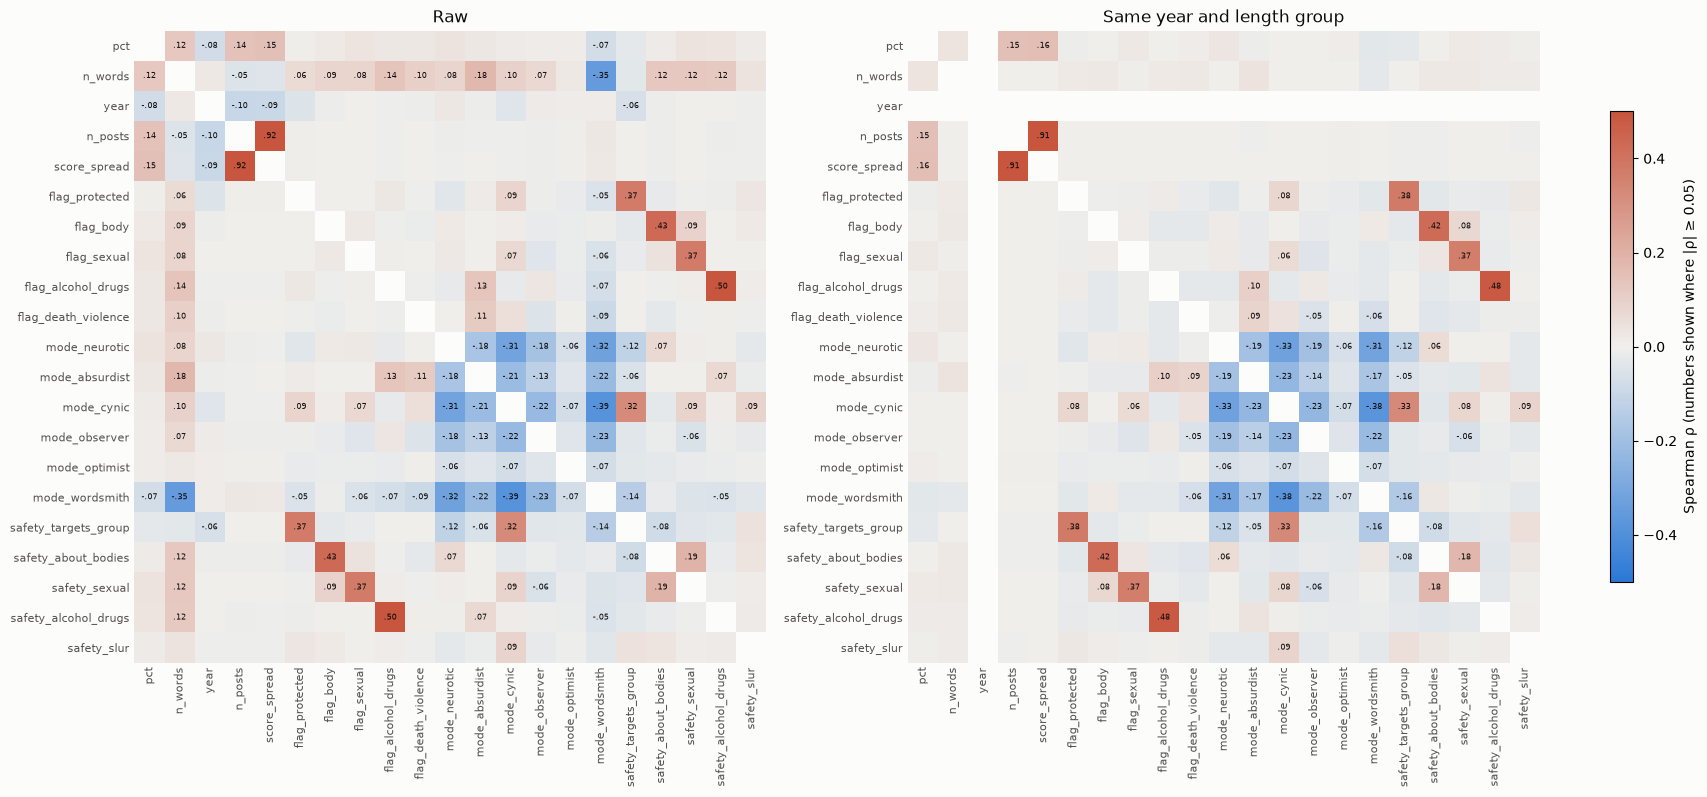

✅ **Rule: no feature needs an extra adjustment, so Exp 10 stands (largest |ρ| with `pct` among flags and safety labels: 0.026, under 0.05)**

✅ **Length has a weak link to upvotes: ρ = +0.127 on all jokes**

✅ **Adjusting for length matters: wordsmith's link to `pct` shrinks from -0.073 to -0.032**

✅ **Length groups don't remove all of length: +0.033 is left within groups, as large as the largest mode link (0.032)**

True

In [7]:
import matplotlib.pyplot as plt
from explorer import rjokes_correlations as corr
cm = run_or_load("rjokes_correlations", corr.run, rerun=RERUN, modes=corr.MODES_PATH, jokes=corr.JOKES_PATH,
                 boots=200, seed=0)
show(f"**All jokes with a year (n = {cm['all_jokes']['n']:,})**\n\n" + corr.table(cm["all_jokes"]))
show(f"**Labeled jokes (n = {cm['labeled']['n']:,})**\n\n" + corr.table(cm["labeled"]))
fig = corr.plot(cm)
display(fig)
plt.close(fig)
every, lab = cm["all_jokes"], cm["labeled"]
adj = dict(zip(lab["names"][1:], lab["adj"]))
raw = dict(zip(lab["names"][1:], lab["raw"]))
tested = [n for n in adj if n.startswith(("flag_", "safety_"))]
modes = [n for n in adj if n.startswith("mode_")]
check(f"Rule: no feature needs an extra adjustment, so Exp 10 stands (largest |ρ| with `pct` among flags and "
      f"safety labels: {max(abs(adj[n]) for n in tested):.3f}, under {cm['rule']['threshold']})",
      cm["rule"]["rerun_for"] == [] and cm["rule"]["look_closer"] == [])
check(f"Length has a weak link to upvotes: ρ = {every['raw'][0]:+.3f} on all jokes",
      0 < every["raw"][0] < 0.2)
check(f"Adjusting for length matters: wordsmith's link to `pct` shrinks from {raw['mode_wordsmith']:+.3f} to "
      f"{adj['mode_wordsmith']:+.3f}", abs(adj["mode_wordsmith"]) < abs(raw["mode_wordsmith"]) * 0.6)
check(f"Length groups don't remove all of length: {adj['n_words']:+.3f} is left within groups, as large as the "
      f"largest mode link ({max(abs(adj[m]) for m in modes):.3f})",
      adj["n_words"] >= max(abs(adj[m]) for m in modes))

**Extra check (decisions.md 2026-11-01, fixed before running):** the rule tests each link separately, so it
misses a weak link paired with a strong one, like `safety_targets_group` (−0.026 with `pct`, +0.325 with cynic).
This re-runs all 4 Exp 10 variants, same resamples, also adjusting for that label. It isn't a rule trigger,
and the label is unreliable (Exp 9), so a change casts doubt on cynic's place; we don't adopt the adjustment.

In [8]:
tg = run_or_load("mode_ranking_targets_group", mode_ranking.run, rerun=RERUN, modes=mode_ranking.MODES_PATH,
                 jokes=mode_ranking.JOKES_PATH, boots=1000, seed=0, also_adjust="targets_group")
show(mode_ranking.table(tg))
tv, tf, mf = tg["variants"], tg["findings"], mr["findings"]
cyn = tg["modes"].index("cynic")
keep = ("neurotic", "optimist", "wordsmith")
check("Main findings hold: C1, C3 and the sides of neurotic, optimist and wordsmith don't change",
      tf["c1"] == mf["c1"] and tf["c3_wordsmith_last"] == mf["c3_wordsmith_last"]
      and all(tf["c2_side_by_mode"][m] == mf["c2_side_by_mode"][m] for m in keep))
check(f"Cynic's place isn't settled: its decile win rate moves from {mr['variants']['WR-d10']['estimate'][cyn]:.3f} "
      f"to {tv['WR-d10']['estimate'][cyn]:.3f}, about the size of the gaps between the middle modes",
      abs(tv["WR-d10"]["estimate"][cyn] - mr["variants"]["WR-d10"]["estimate"][cyn]) > 0.005)

| Mode | Median words | Judge win rate | Raw mean pct | WR-q4 | WR-d10 | REG-q4 | REG-d10 |
|---|---|---|---|---|---|---|---|
| neurotic | 20 | 63.4% | 0.522 | 0.519 [0.515, 0.524] | 0.519 [0.515, 0.524] | +0.009 [+0.004, +0.014] | +0.011 [+0.006, +0.016] |
| absurdist | 25 | 55.8% | 0.521 | 0.504 [0.498, 0.510] | 0.492 [0.486, 0.499] | -0.001 [-0.006, +0.005] | -0.011 [-0.017, -0.005] |
| cynic | 20 | 55.2% | 0.507 | 0.510 [0.505, 0.514] | 0.510 [0.505, 0.514] | +0.001 [-0.003, +0.005] | +0.002 [-0.002, +0.006] |
| observer | 20 | 49.1% | 0.509 | 0.498 [0.492, 0.504] | 0.499 [0.493, 0.505] | -0.003 [-0.009, +0.002] | -0.001 [-0.007, +0.004] |
| optimist | 20 | 41.1% | 0.532 | 0.526 [0.512, 0.543] | 0.526 [0.511, 0.543] | +0.019 [+0.006, +0.032] | +0.020 [+0.008, +0.034] |
| wordsmith | 14 | 34.9% | 0.469 | 0.471 [0.466, 0.475] | 0.475 [0.471, 0.480] | -0.025 [-0.030, -0.021] | -0.021 [-0.026, -0.017] |

WR = win rate vs same-year, similar-length jokes of other modes; REG = effect on pct vs the average mode. [95% bootstrap CI]

| Variant | ρ vs judge [95% CI] | C1 | C2 sides matching (undetermined) | C3 wordsmith last |
|---|---|---|---|---|
| raw means | +0.37 | (not a criterion) | | |
| WR-q4 | +0.37 [+0.26, +0.71] | agree | 3/6 (2) | 100% of resamples |
| WR-d10 | +0.26 [+0.26, +0.60] | agree | 3/6 (1) | 100% of resamples |
| REG-q4 | +0.37 [+0.20, +0.66] | agree | 2/6 (3) | 100% of resamples |
| REG-d10 | +0.26 [+0.20, +0.49] | agree | 2/6 (2) | 100% of resamples |

**Across all 4 variants:** C1 agree; C3 wordsmith last: holds; human side of the field: neurotic above, absurdist depends on the estimator, cynic depends on the estimator, observer undetermined, optimist above, wordsmith below.

✅ **Main findings hold: C1, C3 and the sides of neurotic, optimist and wordsmith don't change**

✅ **Cynic's place isn't settled: its decile win rate moves from 0.501 to 0.510, about the size of the gaps between the middle modes**

True